In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
units = pd.read_csv('units_L234.csv').copy()

In [3]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['strategy_dendrite', 'pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

In [4]:
import pickle
import h5py
import numpy as np
import pandas as pd

# ============================================================
# Paths
# ============================================================

FOUNDATION_PATH = "MICrONS\\readout_info\\foundation_model.pkl"
MICRONS_H5_PATH = "MICrONS\\microns.h5"
COREG_PATH = "coreg_v1300.csv"


# ============================================================
# Load files
# ============================================================

with open(FOUNDATION_PATH, "rb") as f:
    foundation = pickle.load(f)
    """{"session_scan": {
            mu: [mu_x, mu_x] #area of the vision field where focus on the neuron
            feature_weigth: [[128 features] * 4] visual caracteristic of this area learnt by a the model
        }
    }"""

h5 = h5py.File(MICRONS_H5_PATH, "r") #for more information see the folder on hugging face https://huggingface.co/datasets/NeuroBLab/MICrONS

coreg = pd.read_csv(COREG_PATH) #merging table with coreg["session", "scan_idx", "unit_id", "pt_root_id", "residual", "score"]

print(coreg)


# ============================================================
# Build readout table
# ============================================================

def build_readout_df(model_dict, h5, model_name="model"):
    rows = []
    for session_scan, data in model_dict.items():
        if session_scan not in h5["sessions"]:
            print("Missing in h5:", session_scan)
            continue

        session, scan_idx = map(int, session_scan.split("_"))
        meta = h5["sessions"][session_scan]["meta"]
        print(meta.keys())
        unit_ids = meta["unit_ids"][:]
        weights = data["feature_weights"]
        mu = data["mu"]

        n = min(len(unit_ids), weights.shape[0], mu.shape[0])

        if len(unit_ids) != weights.shape[0]:
            print(
                f"WARNING {model_name} {session_scan}: "
                f"unit_ids={len(unit_ids)}, weights={weights.shape[0]}, using n={n}"
            )

        for i in range(n):
            rows.append({
                "model_name": model_name,
                "session": session,
                "scan_idx": scan_idx,
                "unit_id": int(unit_ids[i]),
                "readout_weight": weights[i].reshape(-1).astype(np.float32),
                "readout_mu_x": float(mu[i, 0]),
                "readout_mu_y": float(mu[i, 1]),
            })
    return pd.DataFrame(rows)


readout_df = build_readout_df(foundation, h5)


# ============================================================
# Clean coreg table
# ============================================================

coreg = coreg[
    ["session", "scan_idx", "unit_id", "pt_root_id", "residual", "score"]
].copy()

coreg["session"] = coreg["session"].astype(int)
coreg["scan_idx"] = coreg["scan_idx"].astype(int)
coreg["unit_id"] = coreg["unit_id"].astype(int)
coreg["pt_root_id"] = coreg["pt_root_id"].astype(np.int64)
print(coreg["score"].describe())

print(coreg["residual"].describe())

# ============================================================
# Merge readouts with pt_root_id
# ============================================================

readout_with_root = readout_df.merge(
    coreg,
    on=["session", "scan_idx", "unit_id"],
    how="inner"
)

readout_with_root = readout_with_root[
    (readout_with_root["residual"] < 30)
    & (readout_with_root["score"] > 0)
].copy()

idx = (
    readout_with_root
    .groupby("pt_root_id")["score"]
    .idxmax()
)

readout_unique = (
    readout_with_root
    .loc[idx]
    .reset_index(drop=True)
)

print("readout_df:", readout_df.shape)
print("readout_with_root:", readout_with_root.shape)
print("readout_with_root:", readout_with_root.shape)
print("matched fraction:", len(readout_with_root) / len(readout_df))



       id_ref                       created_ref  valid_ref     volume  \
0      388868  2020-09-28 22:44:53.222573+00:00       True  292.63200   
1      357165  2020-09-28 22:44:28.479993+00:00       True  254.62144   
2      323782  2020-09-28 22:45:16.004514+00:00       True  354.07840   
3      452040  2020-09-28 22:45:19.539072+00:00       True  374.22530   
4      485026  2020-09-28 22:44:53.278972+00:00       True  292.83008   
...       ...                               ...        ...        ...   
83041  326990  2020-09-28 22:43:47.135816+00:00       True  317.94562   
83042  191219  2020-09-28 22:41:37.134630+00:00       True  347.67667   
83043  259262  2020-09-28 22:40:55.410396+00:00       True  334.41168   
83044  422837  2020-09-28 22:42:45.050377+00:00       True  304.70242   
83045  553999  2020-09-28 22:41:18.478532+00:00       True  368.10376   

         pt_supervoxel_id          pt_root_id     id  \
0       97536645708182218  864691135801936738      1   
1       947

              pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0     864691135591234315     855.283508     257.641693     667.000000   
1     864691135474733632     859.143799     312.651459     661.559998   
2     864691135874456206     921.950500     337.162720     658.520020   
3     864691136084469356     862.910950     166.053955     674.440002   
4     864691135156852068     895.572205     134.926117     688.919983   
...                  ...            ...            ...            ...   
6443  864691136032174523     971.227966     138.140182     794.239990   
6444  864691135719735857     928.664246     358.822266     607.880005   
6445  864691135429292592    1028.933472     105.669991     641.440002   
6446  864691136238038799     708.155273     187.977524     799.599976   
6447  864691135386800769    1047.609131      85.332283     751.880005   

     classification_system strategy_axon layer  gOSI_data selective_ori  \
0        excitatory_neuron          none    L4  

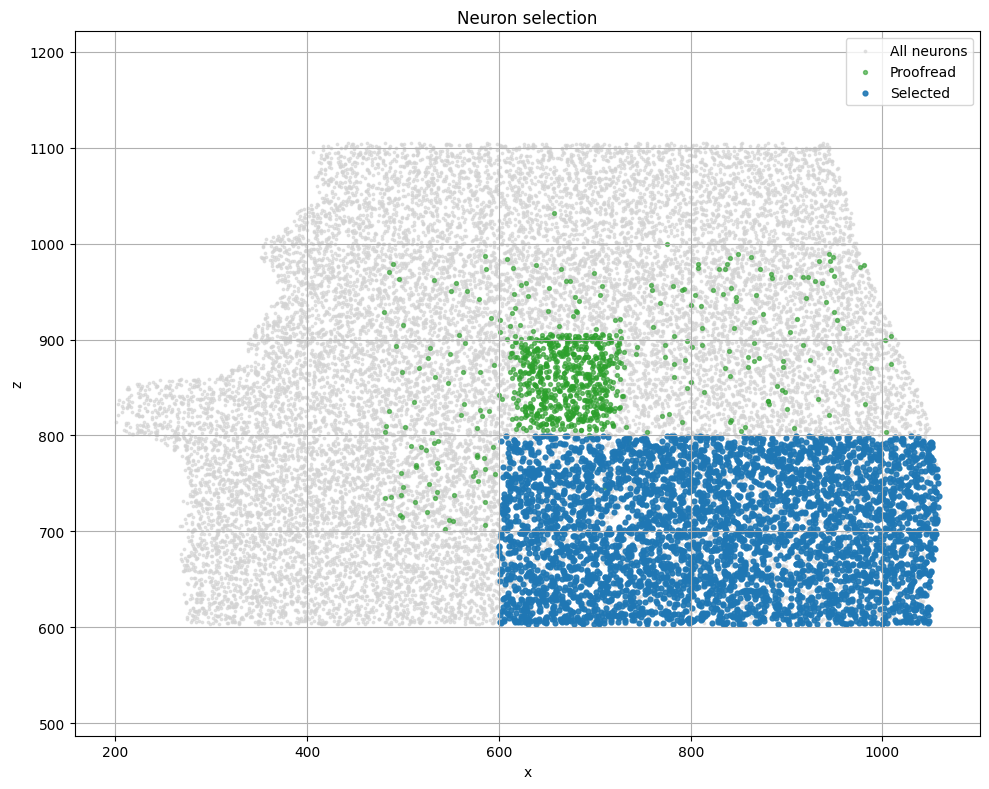

In [5]:
units_cleaned = clean_dataset(units)

selected_mask = units_cleaned[(units_cleaned["pt_position_z"] < 800) & (units_cleaned["pt_position_x"] > 600)]

proofread = units_cleaned[(units_cleaned['strategy_axon'] != 'none')]

selected_mask = selected_mask.merge(readout_unique[ 
    [ "pt_root_id", 
     "readout_weight", 
     "readout_mu_x", 
     "readout_mu_y", 
     "session", 
     "scan_idx", 
     "unit_id", 
     "residual", 
     "score" ] ], 
     on="pt_root_id", how="left" )

print(selected_mask)


selected_mask = selected_mask[
    selected_mask["readout_weight"].notna()
].copy().reset_index(drop=True)

plt.figure(figsize=(10, 8))

# 1. Tout le connectome
plt.scatter(
    units["pt_position_x"],
    units["pt_position_z"],
    s=3,
    alpha=0.6,
    color="lightgray",
    label=f"All neurons"
)

# 2. Neurones proofread
plt.scatter(
    proofread["pt_position_x"],
    proofread["pt_position_z"],
    s=8,
    alpha=0.6,
    color="tab:green",
    label=f"Proofread"
)

# 3. Neurones finalement sélectionnés
plt.scatter(
    selected_mask["pt_position_x"],
    selected_mask["pt_position_z"],
    s=12,
    alpha=0.9,
    color="tab:blue",
    label=f"Selected"
)

plt.xlabel("x")
plt.ylabel("z")

plt.title(
    f"Neuron selection"
)

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.tight_layout()

In [6]:
mask_exc = (selected_mask['classification_system'] == 'excitatory_neuron')
mask_inh = (units_cleaned['classification_system'] == 'inhibitory_neuron')

mask_l23 = (selected_mask['layer'] == 'L2/3')
mask_l4 = (units_cleaned['layer'] == 'L4')



In [7]:
E_L23 = selected_mask[mask_exc & mask_l23].copy().reset_index(drop=True)
I_L23 = units_cleaned[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = units_cleaned[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = units_cleaned[mask_inh & mask_l4].copy().reset_index(drop=True)

In [8]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [9]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [10]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [11]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    
    pre_pop = (
    pre_pop
    .drop_duplicates("pt_root_id")
    .reset_index(drop=True)
)

    post_pop = (
    post_pop
    .drop_duplicates("pt_root_id")
    .reset_index(drop=True)
)
    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
        "readout_weight"
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    """conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        #conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [12]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
        "readout_weight"
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    """all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [13]:
def build_dataset(pre_pop, post_pop, synapses, metric=["Euclidean"]):

    """
    Build dataset for connection prediction.

    Returns
    -------
    X : (n_pairs,2)
        [pre_idx, post_idx]

    y : (n_pairs,)
        labels

    features : list

    V_matrix : (n_neurons,512)

    all_ids : array

    distance : (n_pairs,)
    """

    # ==========================================================
    # Remove duplicate neurons
    # ==========================================================

    pre_pop = (
        pre_pop
        .drop_duplicates("pt_root_id")
        .reset_index(drop=True)
    )

    post_pop = (
        post_pop
        .drop_duplicates("pt_root_id")
        .reset_index(drop=True)
    )


    # ==========================================================
    # Existing connections
    # ==========================================================

    conn_dist = existing_connections_v1(
        pre_pop,
        post_pop,
        synapses,
        metric
    )

    print("Existing:", len(conn_dist))


    # ==========================================================
    # Potential connections
    # ==========================================================

    pot_dist = potential_connections_v1(
        pre_pop,
        post_pop,
        metric
    )

    print("Potential:", len(pot_dist))


    # ==========================================================
    # Remove false negatives
    # ==========================================================

    positive_pairs = set(
        zip(
            conn_dist["pre_pt_root_id"],
            conn_dist["post_pt_root_id"]
        )
    )

    pot_pairs = list(
        zip(
            pot_dist["pre_pt_root_id"],
            pot_dist["post_pt_root_id"]
        )
    )

    mask_negative = [
        pair not in positive_pairs
        for pair in pot_pairs
    ]

    pot_dist = pot_dist[mask_negative].copy()

    print(
        "Potential after filtering:",
        len(pot_dist)
    )


    # ==========================================================
    # Labels
    # ==========================================================

    conn_dist["label"] = 1
    pot_dist["label"] = 0

    df = pd.concat(
        [conn_dist, pot_dist],
        ignore_index=True
    )

    print("Final df:", len(df))


    # ==========================================================
    # Build neuron index map
    # ==========================================================

    all_ids = pd.Index(
        pd.concat([
            df["pre_pt_root_id"],
            df["post_pt_root_id"]
        ]).unique()
    )

    id_map = {
        neuron_id: i
        for i, neuron_id in enumerate(all_ids)
    }


    # ==========================================================
    # Pair indices
    # ==========================================================

    pre_idx = (
        df["pre_pt_root_id"]
        .map(id_map)
        .to_numpy(dtype=np.int64)
    )

    post_idx = (
        df["post_pt_root_id"]
        .map(id_map)
        .to_numpy(dtype=np.int64)
    )

    X = np.stack(
        [pre_idx, post_idx],
        axis=1
    )


    # ==========================================================
    # Build full feature matrix:
    # readout_weight + receptive field coordinates + anatomical xyz
    # ==========================================================

    id_to_features = selected_mask.drop_duplicates("pt_root_id").set_index("pt_root_id")

    # --------------------------
    # 1. Readout weights
    # --------------------------

    V_readout = np.stack(
        id_to_features.loc[np.array(all_ids), "readout_weight"].values
    ).astype(np.float32)

    V_readout = (
        V_readout - V_readout.mean(axis=0, keepdims=True)
    ) / (
        V_readout.std(axis=0, keepdims=True) + 1e-8
    )

    # --------------------------
    # 2. Receptive field center coordinates
    # --------------------------

    V_rf = id_to_features.loc[
        np.array(all_ids),
        ["readout_mu_x", "readout_mu_y"]
    ].to_numpy(dtype=np.float32)

    V_rf = (
        V_rf - V_rf.mean(axis=0, keepdims=True)
    ) / (
        V_rf.std(axis=0, keepdims=True) + 1e-8
    )

    # --------------------------
    # 3. Anatomical coordinates
    # --------------------------

    V_xyz = id_to_features.loc[
        np.array(all_ids),
        ["pt_position_x", "pt_position_y", "pt_position_z"]
    ].to_numpy(dtype=np.float32)

    V_xyz = (
        V_xyz - V_xyz.mean(axis=0, keepdims=True)
    ) / (
        V_xyz.std(axis=0, keepdims=True) + 1e-8
    )

    # --------------------------
    # 4. Optional block weights
    # --------------------------

    w_readout = 1 / np.sqrt(512)
    w_rf = 1 / np.sqrt(2)
    w_xyz = 1 / np.sqrt(3)

    V_matrix = np.concatenate(
        [
            w_readout * V_readout,
            w_rf * V_rf,
            #w_xyz * V_xyz,
        ],
        axis=1
    ).astype(np.float32)


    # ==========================================================
    # Distance (for analysis)
    # ==========================================================

    if "euclidean" in df.columns:

        distance = (
            df["euclidean"]
            .to_numpy(dtype=np.float32)
        )

    else:

        distance = None


    # ==========================================================
    # Labels
    # ==========================================================

    y = df["label"].to_numpy(
        dtype=np.float32
    )


    # ==========================================================
    # Features names
    # ==========================================================

    features = [
        "pre_readout_weight",
        "post_readout_weight"
    ]


    # ==========================================================
    # Diagnostics
    # ==========================================================

    print("n_pairs:", len(y))

    print(
        "n_neurons:",
        len(all_ids)
    )

    print(
        "positive rate:",
        y.mean()
    )

    print(
        "V_matrix shape:",
        V_matrix.shape
    )


    return (
        X,
        y,
        features,
        V_matrix,
        all_ids,
        distance
    )

In [14]:
path, pre, post = pathways[0]
X, y, c, V, _, _ = build_dataset(pre, post, synapses)
print(X)

Existing: 37539
Potential: 6152880
Potential after filtering: 6115341
Final df: 6152880
n_pairs: 6152880
n_neurons: 2481
positive rate: 0.0061010453
V_matrix shape: (2481, 514)
[[   0  935]
 [   1 1603]
 [   2 1238]
 ...
 [ 932 2300]
 [ 932 2268]
 [ 932  235]]


In [15]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import roc_auc_score

# =========================
# Config
# =========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

CHECKPOINT_DIR = "checkpoints_readout_feature_weight_receptive_field_coordinate_30_epoch_5_patience_2_hidden_layers_of_64_neurons_Relu_in_between_bce_lr3_features_normalized_and_weighted"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BATCH_SIZE = 32768
N_EPOCHS = 50
PATIENCE = 10
LR = 1e-3
DIMS = [3]

TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)




Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [16]:
class ReadoutMLP(nn.Module):
    def __init__(self, V_matrix, hidden=64):
        super().__init__()

        V_matrix = torch.as_tensor(
            V_matrix,
            dtype=torch.float32
        )

        self.register_buffer("V", V_matrix)

        input_dim = 2 * V_matrix.shape[1]

        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward_logits(self, X):
        pre_idx = X[:, 0].long()
        post_idx = X[:, 1].long()

        V_pre = self.V[pre_idx]
        V_post = self.V[post_idx]

        x = torch.cat(
            [V_pre, V_post],
            dim=1
        )

        return self.mlp(x).squeeze(1)

    def forward(self, X):
        return torch.sigmoid(
            self.forward_logits(X)
        )

In [17]:
# =========================
# Data
# =========================

X, y, _, V, _, _ = build_dataset(
    pre, post, synapses,
    metric=["Euclidean"]
)

y = torch.tensor(y, dtype=torch.float32)
X = torch.tensor(X, dtype=torch.float32)

n_neurons = int(max(X[:,0].max(), X[:,1].max()).item()) + 1
print("n_neurons:", n_neurons)
print("n_pairs:", len(y))
print("positive rate:", y.mean().item())

y = y.to(DEVICE)
X = X.to(DEVICE)

dataset = TensorDataset(X,  y)

n_total = len(dataset)
n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

Existing: 37539


Potential: 6152880
Potential after filtering: 6115341
Final df: 6152880
n_pairs: 6152880
n_neurons: 2481
positive rate: 0.0061010453
V_matrix shape: (2481, 514)
n_neurons: 2481
n_pairs: 6152880
positive rate: 0.0061010452918708324


In [18]:
# =========================
# Eval
# =========================

def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_y = []
    all_preds = []

    with torch.no_grad():
        for X, yb in loader:

            logits = model.forward_logits(X)
            loss = criterion(logits, yb)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(yb)
            all_y.append(yb.cpu().numpy())
            all_preds.append(probs.cpu().numpy())

    all_y = np.concatenate(all_y)
    all_preds = np.concatenate(all_preds)

    auc = roc_auc_score(all_y, all_preds)

    return total_loss / len(loader.dataset), auc


In [19]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    torch.save({
        "dim": dim,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # Best metrics
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Early stopping state
        "epochs_without_improvement": epochs_without_improvement,

        # Saved results
        "results": results,

        # RNG states for reproducibility
        "rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "numpy_rng_state": np.random.get_state(),
    }, path)


def load_checkpoint(path, model, optimizer):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore model and optimizer
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    # Restore CPU RNG state if compatible
    rng_state = ckpt.get("rng_state", None)
    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(rng_state.cpu())
        except Exception as e:
            print("Warning: CPU rng_state ignored:", e)
    else:
        print("Warning: CPU rng_state ignored.")

    # Restore CUDA RNG state if compatible
    cuda_rng_state = ckpt.get("cuda_rng_state", None)
    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(cuda_rng_state)
        except Exception as e:
            print("Warning: CUDA rng_state ignored:", e)

    # Restore NumPy RNG state if compatible
    numpy_rng_state = ckpt.get("numpy_rng_state", None)
    if numpy_rng_state is not None:
        try:
            np.random.set_state(numpy_rng_state)
        except Exception as e:
            print("Warning: NumPy rng_state ignored:", e)

    return ckpt

In [20]:
import os

dim = 1  # change selon la dimension qui plante
"""bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")

if os.path.exists(bad_path):
    os.remove(bad_path)
    print("Deleted:", bad_path)"""

'bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")\n\nif os.path.exists(bad_path):\n    os.remove(bad_path)\n    print("Deleted:", bad_path)'

In [21]:
import csv

log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

# Créer le fichier avec en-tête s'il n'existe pas
if not os.path.exists(log_csv_path):
    with open(log_csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "dim",
            "epoch",
            "train_loss",
            "val_loss",
            "val_auc"
        ])

In [22]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    # Créer le CSV s'il n'existe pas
    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = ReadoutMLP(
    V_matrix=V,
    hidden=64
    ).to(DEVICE)

    # Loss pondérée pour gérer le fort déséquilibre
    pos_weight = (y == 0).sum() / (y == 1).sum()
    #criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================
    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get(
            "epochs_without_improvement", 0
        )
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================
    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for Z, yb in train_loader:
            logits = model.forward_logits(Z)
            loss = criterion(logits, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        # Log CSV
        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on AUC
        # =========================
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results
            )
        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================
        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results
        )

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================
    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    # Remove previous result for this dimension
    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )

# =========================
# Final save
# =========================
with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)


Training dim = 3
dim=03 | epoch=000 | train_loss=0.3361 | val_loss=0.0847 | val_auc=0.4880
dim=03 | epoch=001 | train_loss=0.0546 | val_loss=0.0423 | val_auc=0.5436
dim=03 | epoch=002 | train_loss=0.0393 | val_loss=0.0378 | val_auc=0.6098
dim=03 | epoch=003 | train_loss=0.0368 | val_loss=0.0363 | val_auc=0.6697
dim=03 | epoch=004 | train_loss=0.0356 | val_loss=0.0354 | val_auc=0.7139
dim=03 | epoch=005 | train_loss=0.0348 | val_loss=0.0347 | val_auc=0.7450
dim=03 | epoch=006 | train_loss=0.0341 | val_loss=0.0341 | val_auc=0.7693
dim=03 | epoch=007 | train_loss=0.0335 | val_loss=0.0335 | val_auc=0.7914
dim=03 | epoch=008 | train_loss=0.0329 | val_loss=0.0330 | val_auc=0.8084
dim=03 | epoch=009 | train_loss=0.0323 | val_loss=0.0325 | val_auc=0.8216
dim=03 | epoch=010 | train_loss=0.0318 | val_loss=0.0321 | val_auc=0.8333
dim=03 | epoch=011 | train_loss=0.0314 | val_loss=0.0317 | val_auc=0.8422
dim=03 | epoch=012 | train_loss=0.0310 | val_loss=0.0313 | val_auc=0.8509
dim=03 | epoch=013 |

Existing: 37539
Potential: 6152880
Potential after filtering: 6115341
Final df: 6152880
n_pairs: 6152880
n_neurons: 2481
positive rate: 0.0061010453
V_matrix shape: (2481, 514)
X shape: torch.Size([6152880, 2])
y shape: torch.Size([6152880])
V_matrix shape: (2481, 514)
features: ['pre_readout_weight', 'post_readout_weight']
Loaded model for dim=3
Best epoch: 49
Best val loss: 0.0317
p_pred shape: (6152880,)
distance shape: (6152880,)


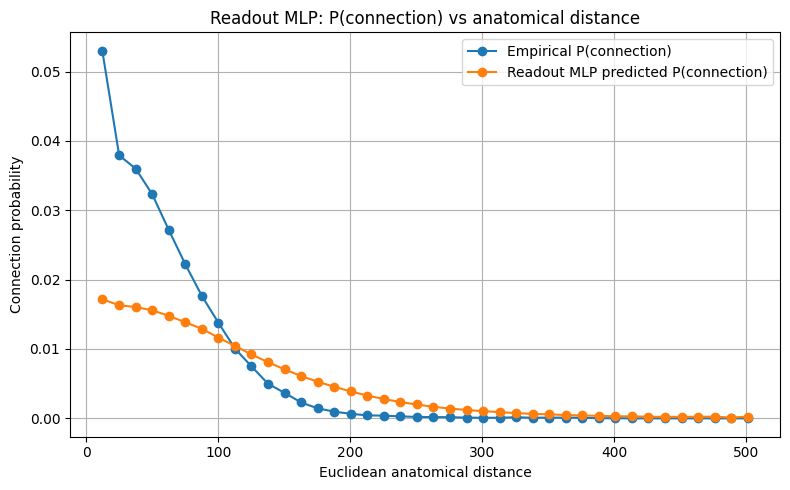

Saved: baselines\readout_mlp_probability_vs_distance.csv


In [21]:
# =========================
# Load best Readout MLP model
# =========================

import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DIM_TO_ANALYZE = 3
CHECKPOINT_DIR = "checkpoints_readout_feature_weight_receptive_field_coordinate_30_epoch_5_patience_2_hidden_layers_of_64_neurons_Relu_in_between_bce_lr3_features_normalized_and_weighted"

ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{DIM_TO_ANALYZE}.pt")

if not os.path.exists(ckpt_path):
    raise FileNotFoundError(f"Checkpoint not found: {ckpt_path}")


# =========================
# Build dataset
# =========================

X, y, features, V_matrix, all_ids, _ = build_dataset(
    pre,
    post,
    synapses,
    metric=["Euclidean"]
)

X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.float32)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("V_matrix shape:", V_matrix.shape)
print("features:", features)


# =========================
# Recreate and load model
# =========================

model = ReadoutMLP(
    V_matrix=V_matrix,
    hidden=64
).to(DEVICE)

ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")


# =========================
# Predict probabilities
# =========================

batch_size = 32768
all_probs = []

with torch.no_grad():
    for start in range(0, len(X), batch_size):
        xb = X[start:start + batch_size].to(DEVICE)
        p_batch = model(xb)
        all_probs.append(p_batch.cpu().numpy())

p_pred = np.concatenate(all_probs)

print("p_pred shape:", p_pred.shape)


# =========================
# Compute anatomical distances
# =========================

X_np = X.numpy()

pre_idx = X_np[:, 0]
post_idx = X_np[:, 1]

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx]
post_ids = idx_to_id[post_idx]

id_to_pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = id_to_pos.loc[pre_ids].to_numpy()
post_pos = id_to_pos.loc[post_ids].to_numpy()

distance = np.linalg.norm(pre_pos - post_pos, axis=1)

print("distance shape:", distance.shape)


# =========================
# Build curve dataframe
# =========================

df_curve = pd.DataFrame({
    "distance": distance,
    "y": y.numpy(),
    "p_pred": p_pred,
})

df_curve["bin"] = pd.cut(
    df_curve["distance"],
    bins=40
)

curve = (
    df_curve
    .groupby("bin", observed=True)
    .agg(
        empirical_prob=("y", "mean"),
        predicted_prob=("p_pred", "mean"),
        n_pairs=("y", "size"),
        n_connections=("y", "sum"),
    )
    .reset_index()
)

curve["bin_center"] = curve["bin"].apply(lambda b: b.mid)


# =========================
# Plot
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    curve["bin_center"],
    curve["empirical_prob"],
    marker="o",
    label="Empirical P(connection)"
)

plt.plot(
    curve["bin_center"],
    curve["predicted_prob"],
    marker="o",
    label="Readout MLP predicted P(connection)"
)

plt.xlabel("Euclidean anatomical distance")
plt.ylabel("Connection probability")
plt.title("Readout MLP: P(connection) vs anatomical distance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# =========================
# Save curve
# =========================

BASELINE_DIR = "baselines"
os.makedirs(BASELINE_DIR, exist_ok=True)

baseline_path = os.path.join(
    BASELINE_DIR,
    "readout_mlp_probability_vs_distance.csv"
)

curve.to_csv(baseline_path, index=False)

print("Saved:", baseline_path)

In [22]:
# =========================
# Bootstrap AUC for Readout MLP
# =========================

from sklearn.metrics import roc_auc_score
import numpy as np

def bootstrap_auc(y_true, y_score, n_boot=200, seed=42):
    rng = np.random.default_rng(seed)

    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    n = len(y_true)
    aucs = np.empty(n_boot, dtype=np.float32)

    base_auc = roc_auc_score(y_true, y_score)

    for b in range(n_boot):
        if b % 50 == 0:
            print(f"bootstrap {b}/{n_boot}", flush=True)

        idx = rng.integers(0, n, size=n)
        aucs[b] = roc_auc_score(y_true[idx], y_score[idx])

    return {
        "auc": float(base_auc),
        "ci_low": float(np.percentile(aucs, 2.5)),
        "ci_high": float(np.percentile(aucs, 97.5)),
        "std": float(aucs.std()),
    }


# =========================
# Predict on full dataset by batches
# =========================

batch_size = 32768
all_probs = []

model.eval()

with torch.no_grad():
    for start in range(0, len(X), batch_size):
        xb = X[start:start + batch_size].to(DEVICE)
        p_batch = model(xb)

        all_probs.append(
            p_batch.detach().cpu().numpy()
        )

p_pred = np.concatenate(all_probs)
y_np = y.detach().cpu().numpy()

print("p_pred shape:", p_pred.shape)
print("y shape:", y_np.shape)

# =========================
# Bootstrap
# =========================

test_idx = np.array(test_set.indices)

y_test = y_np[test_idx]
p_test = p_pred[test_idx]

bootstrap_res = bootstrap_auc(
    y_test,
    p_test,
    n_boot=200,
    seed=42 + DIM_TO_ANALYZE
)

print(
    f"Readout MLP test only | "
    f"AUC={bootstrap_res['auc']:.4f} | "
    f"95% CI=[{bootstrap_res['ci_low']:.4f}, {bootstrap_res['ci_high']:.4f}] | "
    f"std={bootstrap_res['std']:.6f}"
)

p_pred shape: (6152880,)
y shape: (6152880,)
bootstrap 0/200
bootstrap 50/200
bootstrap 100/200
bootstrap 150/200
Readout MLP test only | AUC=0.8406 | 95% CI=[0.8346, 0.8468] | std=0.002978
